# Parkinson’s Keystroke Pipeline — Expanded EDA

This notebook is the interactive EDA companion to `scripts/02_eda.py`. It imports the canonical project functions from `src/`; it does not create a second implementation of cleaning or MACD. The analysis is descriptive and subject-level where appropriate. It is intended to explain the data, motivate timing-volatility features, identify quality issues, and document cohort differences before modeling.

**Research caution:** these plots support feature motivation, but they do not establish causality or clinical validity.

In [1]:
from pathlib import Path
import sys, json, warnings
ROOT = Path.cwd().resolve()
if ROOT.name != "parkinsons-keystroke":
    ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists()), Path.cwd())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from src import config
from src.data_loading import load_processed
from src.eda import subject_summary_rows, summarize_sessions
from src.features import macd, macd_with_count

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("colorblind")
RNG = np.random.default_rng(config.SEED)
sessions = load_processed()
subject_rows = pd.DataFrame(subject_summary_rows(sessions))
summary = summarize_sessions(sessions)
print(f"Project root: {ROOT}")
print(f"Sessions: {len(sessions):,} | Subjects: {subject_rows.subject_id.nunique():,} | Cohorts: {sorted(subject_rows.cohort.unique())}")

Project root: /home/ubuntu/parkinsons-keystroke
Sessions: 116 | Subjects: 85 | Cohorts: ['MIT-CS1PD', 'MIT-CS2PD']


## 1. Dataset overview and label balance

The first checks establish how many sessions and subjects are available, whether the cohorts have different sizes, and whether PD/control labels are balanced. Counts are reported at both the session and subject levels because multiple sessions can belong to one participant.

Cohort and label summary


,cohort,label_name,subjects,mean_subject_keystrokes,median_subject_macd
0,MIT-CS1PD,Control,13,3092.0769,0.0222
1,MIT-CS1PD,PD,18,2688.0556,0.0390
2,MIT-CS2PD,Control,30,1553.3333,0.0215
3,MIT-CS2PD,PD,24,1364.9583,0.0337


,cohort,sessions,subjects,pd_subjects,control_subjects,keystrokes_min,keystrokes_median,keystrokes_max
0,MIT-CS1PD,62.0,31.0,18.0,13.0,443.0,1188.0,3322.0
1,MIT-CS2PD,54.0,54.0,24.0,30.0,299.0,1503.0,3181.0


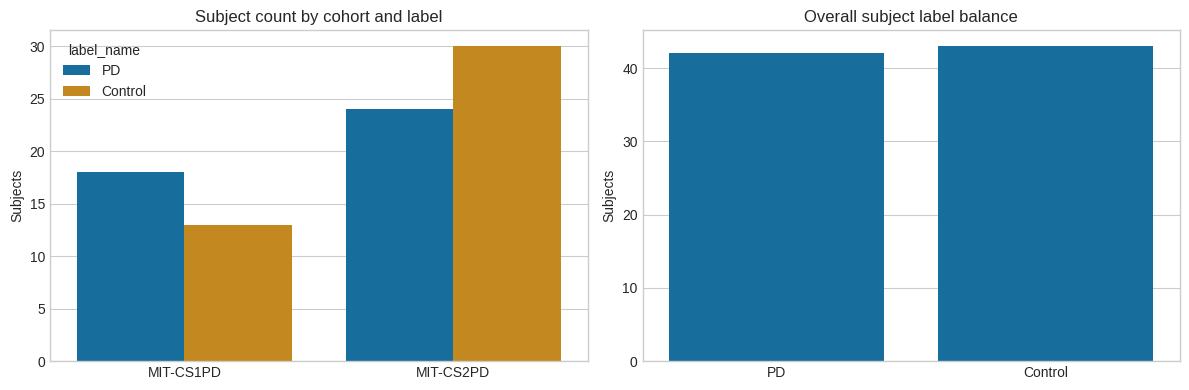

In [2]:
overview = (subject_rows.groupby(["cohort", "label_name"], as_index=False)
             .agg(subjects=("subject_id", "nunique"),
                  mean_subject_keystrokes=("n_keystrokes", "mean"),
                  median_subject_macd=("macd", "median")))
print("Cohort and label summary")
display(overview.round(4))

cohort_counts = pd.DataFrame(summary["by_cohort"]).T.reset_index(names="cohort")
display(cohort_counts)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=subject_rows, x="cohort", hue="label_name", ax=axes[0])
axes[0].set_title("Subject count by cohort and label")
axes[0].set_xlabel("")
axes[0].set_ylabel("Subjects")
sns.countplot(data=subject_rows, x="label_name", ax=axes[1])
axes[1].set_title("Overall subject label balance")
axes[1].set_xlabel("")
axes[1].set_ylabel("Subjects")
plt.tight_layout()
plt.show()

## 2. Cleaning and data-quality audit

The preparation stage records rejected rows by reason. This is important because timing features are sensitive to malformed timestamps, time reversals, extreme hold values, and unwanted key events. The audit is descriptive; rows were cleaned before this notebook loaded the processed sessions.

Audit rows: 116


,raw_rows,parsed_rows,removed_invalid,removed_time_reversal,removed_mouse,removed_long_modifier,removed_backspace,final_rows
total,177513,177513,1174,3504,794,1179,4048,167941


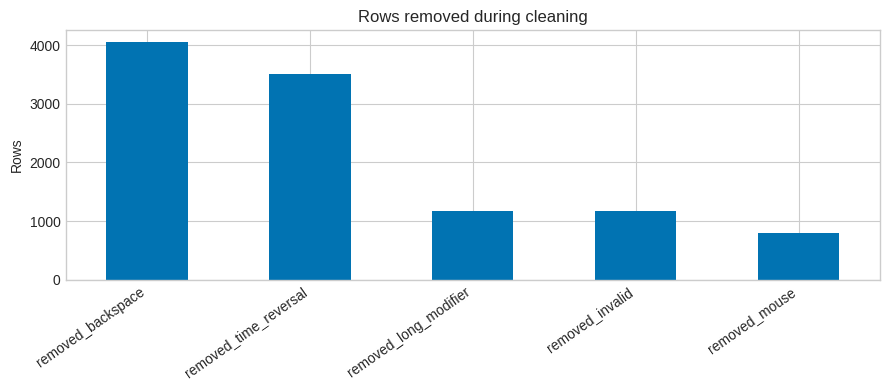

In [3]:
audit_path = ROOT / "data" / "processed" / "cleaning_summary.json"
audit = pd.DataFrame(json.loads(audit_path.read_text()))
quality_cols = [c for c in ["raw_rows", "parsed_rows", "removed_invalid", "removed_time_reversal", "removed_mouse", "removed_long_modifier", "removed_backspace", "final_rows"] if c in audit]
print(f"Audit rows: {len(audit):,}")
if quality_cols:
    display(audit[quality_cols].sum().to_frame("total").T)
    reason_cols = [c for c in quality_cols if c.startswith("removed_")]
    quality_plot = audit[reason_cols].sum().sort_values(ascending=False)
    quality_plot.plot(kind="bar", figsize=(9, 4), title="Rows removed during cleaning")
    plt.ylabel("Rows")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No cleaning audit columns were available.")

## 3. Session length and recording coverage

A model can be affected by how much typing is available. We inspect the number of valid keystrokes per session and compare session lengths across cohorts and labels. The later keystroke-count analysis evaluates how performance changes when sessions are truncated.

count     mean     std    min      25%     50%      75%  \
cohort    label_name                                                            
MIT-CS1PD Control      26.0  1546.04  695.43  855.0  1126.50  1249.5  1820.50   
          PD           36.0  1344.03  582.27  443.0  1079.25  1170.5  1434.00   
MIT-CS2PD Control      30.0  1553.33  753.38  299.0  1113.50  1588.0  1887.25   
          PD           24.0  1364.96  457.36  485.0  1047.25  1398.0  1655.00   

                         max  
cohort    label_name          
MIT-CS1PD Control     3322.0  
          PD          2647.0  
MIT-CS2PD Control     3181.0  
          PD          2206.0

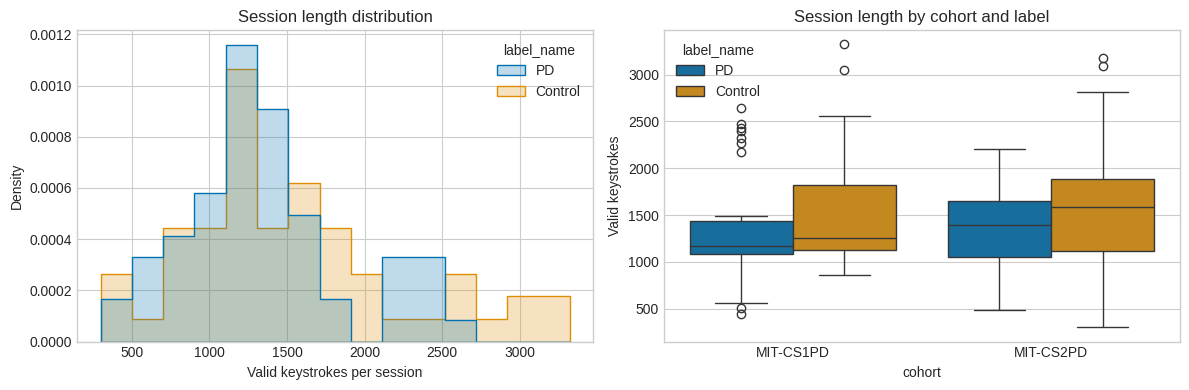

In [4]:
session_df = pd.DataFrame([{
    "session_id": s.session_id, "subject_id": s.subject_id, "cohort": s.cohort,
    "label_name": "PD" if s.label else "Control", "label": s.label,
    "n_keystrokes": len(s.hold_times_s),
    "mean_hold": float(np.mean(s.hold_times_s)),
    "std_hold": float(np.std(s.hold_times_s)),
} for s in sessions])
display(session_df.groupby(["cohort", "label_name"])["n_keystrokes"].describe().round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=session_df, x="n_keystrokes", hue="label_name", bins=15, element="step", stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Session length distribution")
axes[0].set_xlabel("Valid keystrokes per session")
sns.boxplot(data=session_df, x="cohort", y="n_keystrokes", hue="label_name", ax=axes[1])
axes[1].set_title("Session length by cohort and label")
axes[1].set_ylabel("Valid keystrokes")
plt.tight_layout()
plt.show()

## 4. Hold-time distribution

Hold time is the interval between a key press and release. We compare its distribution across labels, report robust quantiles, and inspect whether PD sessions appear shifted or more dispersed. This is a descriptive baseline, not yet the MACD motivation.

Hold-time quantiles by label


,0.01,0.25,0.50,0.75,0.99
label_name,,,,,
Control,0.0443,0.0739,0.0932,0.1240,0.2080
PD,0.0452,0.0853,0.1211,0.1651,0.3329


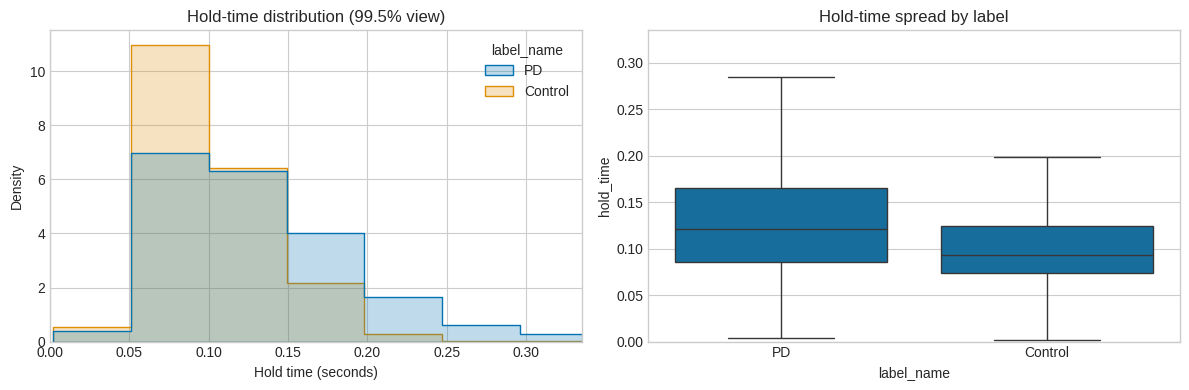

In [5]:
hold_records=[]
for s in sessions:
    # Sample for plotting only so the notebook remains lightweight; all summaries use full arrays.
    x=np.asarray(s.hold_times_s, dtype=float)
    if len(x)>1500: x=RNG.choice(x,1500,replace=False)
    hold_records.extend({"cohort":s.cohort,"label_name":"PD" if s.label else "Control","hold_time":v} for v in x)
hold_df=pd.DataFrame(hold_records)
print("Hold-time quantiles by label")
display(hold_df.groupby("label_name")["hold_time"].quantile([.01,.25,.5,.75,.99]).unstack().round(4))
fig, axes=plt.subplots(1,2,figsize=(12,4))
sns.histplot(data=hold_df,x="hold_time",hue="label_name",bins=50,stat="density",common_norm=False,element="step",ax=axes[0])
axes[0].set_xlim(0, min(0.5, hold_df.hold_time.quantile(.995)))
axes[0].set_title("Hold-time distribution (99.5% view)")
axes[0].set_xlabel("Hold time (seconds)")
sns.boxplot(data=hold_df,x="label_name",y="hold_time",showfliers=False,ax=axes[1])
axes[1].set_ylim(0, min(0.5, hold_df.hold_time.quantile(.995)))
axes[1].set_title("Hold-time spread by label")
plt.tight_layout(); plt.show()

## 5. Consecutive timing change and volatility

MACD is motivated by dynamics: how much one hold time changes from the next. We calculate the mean absolute consecutive change inside each session and aggregate it to the subject level. Larger values indicate more rapid timing variation, but are not inherently pathological.

Volatility summaries by label


mean_abs_change                                                  \
                     count    mean     std     min     25%     50%     75%   
label_name                                                                   
Control               43.0  0.0280  0.0093  0.0114  0.0202  0.0280  0.0345   
PD                    42.0  0.0464  0.0183  0.0169  0.0336  0.0431  0.0524   

                   session_std                                          \
               max       count    mean     std     min     25%     50%   
label_name                                                               
Control     0.0419        43.0  0.0294  0.0101  0.0124  0.0223  0.0284   
PD          0.0999        42.0  0.0474  0.0180  0.0175  0.0330  0.0442   

                            
               75%     max  
label_name                  
Control     0.0365  0.0551  
PD          0.0595  0.0867

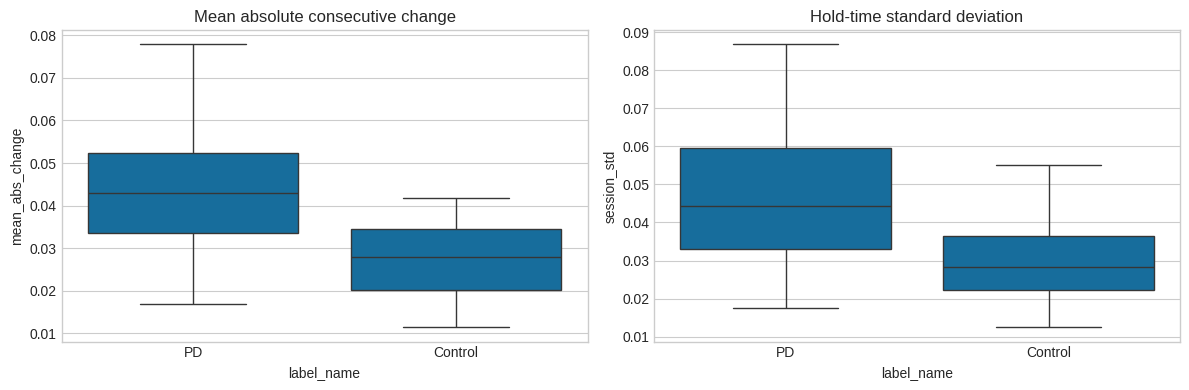

In [6]:
vol_rows=[]
for s in sessions:
    x=np.asarray(s.hold_times_s,dtype=float)
    d=np.abs(np.diff(x))
    vol_rows.append({"subject_id":s.subject_id,"cohort":s.cohort,"label_name":"PD" if s.label else "Control","mean_abs_change":float(np.mean(d)) if len(d) else np.nan,"session_std":float(np.std(x))})
vol_df=pd.DataFrame(vol_rows).groupby(["cohort","subject_id","label_name"],as_index=False).mean(numeric_only=True)
print("Volatility summaries by label")
display(vol_df.groupby("label_name")[["mean_abs_change","session_std"]].describe().round(4))
fig, axes=plt.subplots(1,2,figsize=(12,4))
sns.boxplot(data=vol_df,x="label_name",y="mean_abs_change",showfliers=False,ax=axes[0]); axes[0].set_title("Mean absolute consecutive change")
sns.boxplot(data=vol_df,x="label_name",y="session_std",showfliers=False,ax=axes[1]); axes[1].set_title("Hold-time standard deviation")
plt.tight_layout(); plt.show()

## 6. Subject-level hold time versus volatility

This is the key motivation plot. Each point is one subject. The x-axis is the subject's mean hold time and the y-axis is the subject's mean absolute consecutive change. Color indicates the label and marker shape indicates the cohort. Separation would support investigating a dynamic feature such as MACD, while overlap would show why the task is not perfectly separable.

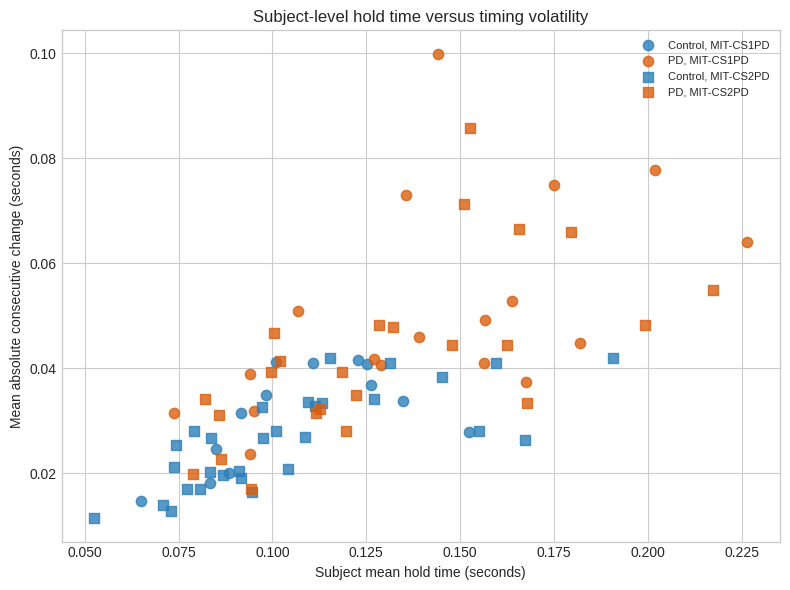

Pearson/Spearman correlations


,mean_hold,mean_abs_change,macd,stdev_hold
mean_hold,1.000,0.687,0.588,0.660
mean_abs_change,0.687,1.000,0.876,0.926
macd,0.588,0.876,1.000,0.899
stdev_hold,0.660,0.926,0.899,1.000


In [7]:
plot_df=subject_rows.merge(vol_df[["subject_id","cohort","mean_abs_change"]],on=["subject_id","cohort"],how="left")
fig,ax=plt.subplots(figsize=(8,6))
colors={"Control":"#2c7fb8","PD":"#d95f0e"}; markers={"MIT-CS1PD":"o","MIT-CS2PD":"s"}
for cohort in sorted(plot_df.cohort.unique()):
    for label in ["Control","PD"]:
        q=plot_df[(plot_df.cohort==cohort)&(plot_df.label_name==label)]
        ax.scatter(q.mean_hold,q.mean_abs_change,c=colors[label],marker=markers[cohort],s=55,alpha=.8,label=f"{label}, {cohort}")
ax.set_xlabel("Subject mean hold time (seconds)"); ax.set_ylabel("Mean absolute consecutive change (seconds)")
ax.set_title("Subject-level hold time versus timing volatility")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print("Pearson/Spearman correlations")
display(plot_df[["mean_hold","mean_abs_change","macd","stdev_hold"]].corr(method="pearson").round(3))

## 7. MACD distribution and corridor diagnostics

MACD keeps consecutive pairs whose two hold times lie in the session-specific 60th–100th percentile corridor. We inspect subject-level MACD by label and cohort, plus how many valid corridor pairs contribute to each session feature. This directly connects the EDA to the primary model.

Session MACD summary


macd                                                          \
           count    mean     std     min     25%     50%     75%     max   
label_name                                                                 
Control     56.0  0.0231  0.0079  0.0087  0.0183  0.0217  0.0277  0.0417   
PD          60.0  0.0429  0.0203  0.0135  0.0300  0.0356  0.0494  0.1095   

           corridor_pairs                                                   \
                    count      mean       std   min     25%    50%     75%   
label_name                                                                   
Control              56.0  257.1071  130.9623  51.0  161.50  240.5  309.50   
PD                   60.0  232.6000  102.8389  78.0  175.75  218.5  279.75   

                   
              max  
label_name         
Control     629.0  
PD          553.0

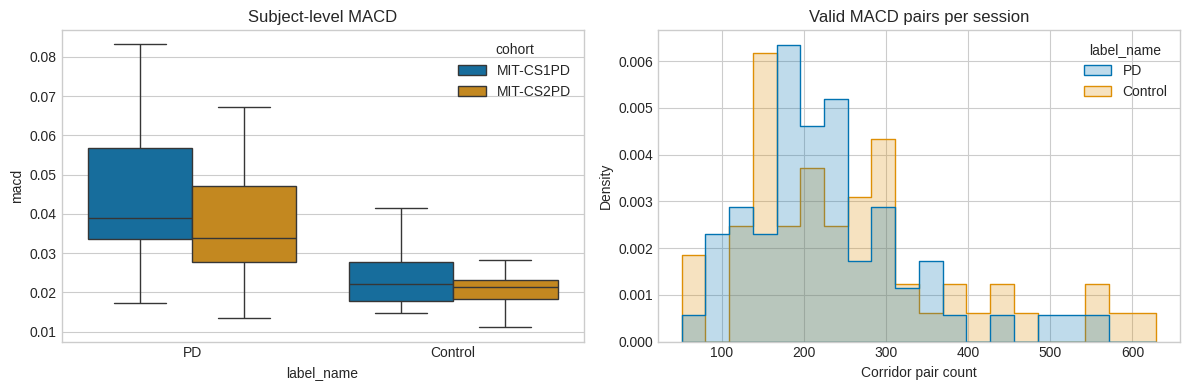

Cohort-label MACD means


count     mean   median      std
cohort    label_name                                  
MIT-CS1PD Control        13  0.02417  0.02217  0.00757
          PD             18  0.04693  0.03902  0.02190
MIT-CS2PD Control        30  0.02212  0.02147  0.00783
          PD             24  0.03683  0.03374  0.01432

In [8]:
macd_rows=[]
for s in sessions:
    value,pairs=macd_with_count(s.hold_times_s,config.CORRIDOR_LOW,config.CORRIDOR_HIGH)
    macd_rows.append({"session_id":s.session_id,"subject_id":s.subject_id,"cohort":s.cohort,"label_name":"PD" if s.label else "Control","macd":value,"corridor_pairs":pairs})
macd_df=pd.DataFrame(macd_rows)
print("Session MACD summary")
display(macd_df.groupby("label_name")[["macd","corridor_pairs"]].describe().round(4))
fig, axes=plt.subplots(1,2,figsize=(12,4))
sns.boxplot(data=subject_rows,x="label_name",y="macd",hue="cohort",showfliers=False,ax=axes[0]); axes[0].set_title("Subject-level MACD")
sns.histplot(data=macd_df,x="corridor_pairs",hue="label_name",bins=20,element="step",stat="density",common_norm=False,ax=axes[1]); axes[1].set_title("Valid MACD pairs per session"); axes[1].set_xlabel("Corridor pair count")
plt.tight_layout(); plt.show()
print("Cohort-label MACD means")
display(subject_rows.groupby(["cohort","label_name"])["macd"].agg(["count","mean","median","std"]).round(5))

## 8. Feature correlation and simple separability

Correlation is not a causal analysis, but it helps identify redundant summaries. We also compare the distributions of mean hold, hold-time spread, volatility, and MACD. These plots are useful for explaining why MACD adds a dynamic perspective beyond a single average.

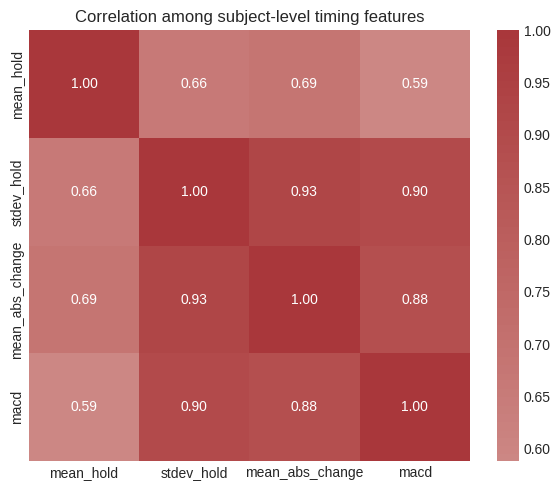

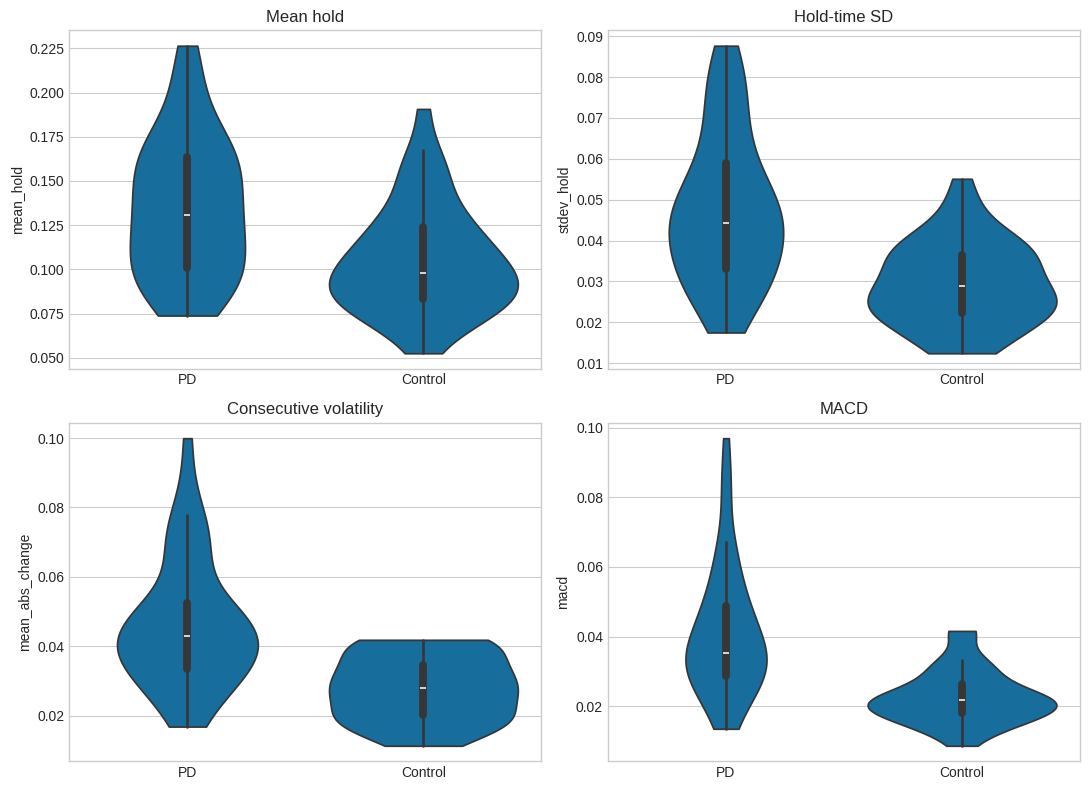

In [9]:
eda_features=plot_df[["label_name","mean_hold","stdev_hold","mean_abs_change","macd"]].copy()
fig,ax=plt.subplots(figsize=(6,5)); sns.heatmap(eda_features.drop(columns="label_name").corr(),annot=True,fmt=".2f",cmap="vlag",center=0,ax=ax); ax.set_title("Correlation among subject-level timing features"); plt.tight_layout(); plt.show()
fig,axes=plt.subplots(2,2,figsize=(11,8))
for ax,field,title in zip(axes.ravel(),["mean_hold","stdev_hold","mean_abs_change","macd"],["Mean hold","Hold-time SD","Consecutive volatility","MACD"]):
    sns.violinplot(data=eda_features,x="label_name",y=field,inner="box",cut=0,ax=ax); ax.set_title(title); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## 9. Main EDA conclusions

The EDA should be read as motivation and quality assurance:

- Mean hold time and hold-time spread provide simple baselines.
- Consecutive change measures timing volatility directly.
- The hold-time-versus-volatility scatter plot shows whether PD and control subjects occupy visibly different regions while retaining overlap.
- MACD focuses that dynamic information on the upper hold-time corridor used by the paper-compatible model.
- Cohort differences and wide overlap mean that a strong-looking plot alone cannot establish clinical validity.
- The final decision about model performance is made by the subject-safe cross-cohort evaluation pipeline, not by choosing a favorable EDA plot.